# Tugas 1 — Data Preprocessing
## Kasus: Analisis Data Pasien Rawat Inap Rumah Sakit

**Nama:** Muhammad Adi Indrawan  
**NIM:** 3022410001  
**Partner / pembuat kasus:** Muhammad Endi Saputra Ramadhan (3022410040)

Notebook ini berisi tahapan eksplorasi, pembersihan, transformasi, encoding, analisis korelasi, scaling, dan PCA pada dataset `data_pasien_rs_kotor.csv` (418 baris, 23 variabel). Dataset berasal dari partner dan sengaja mengandung berbagai masalah kualitas data.

> Catatan: untuk menjalankan di Google Colab, unggah `data_pasien_rs_kotor.csv` ke `/content` atau jalankan sel upload yang tersedia.


## 0. Persiapan

**Input:** file `data_pasien_rs_kotor.csv`.  
**Proses:** memuat library dan data tanpa mengubah tipe (semua dibaca sebagai string agar format asli terlihat).  
**Output:** objek DataFrame `df_raw` dan `df` beserta ukurannya.


In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

os.makedirs("gambar", exist_ok=True)

PATH = "data_pasien_rs_kotor.csv"
if not os.path.exists(PATH) and os.path.exists("/content/data_pasien_rs_kotor.csv"):
    PATH = "/content/data_pasien_rs_kotor.csv"
if not os.path.exists(PATH):
    from google.colab import files
    uploaded = files.upload()
    PATH = list(uploaded.keys())[0]

df_raw = pd.read_csv(PATH, dtype=str)
df = df_raw.copy()

print("Ukuran data mentah:", df.shape)
df.head()


Ukuran data mentah: (418, 23)


,ID_Pasien,Nama_Pasien,Kode_RS,Jenis_Kelamin,Usia,Berat_Badan,Tinggi_Badan,BMI,Tekanan_Sistolik,Tekanan_Diastolik,Gula_Darah,Kolesterol,Detak_Jantung,Diagnosis,Jenis_Asuransi,Ruang_Rawat,Tanggal_Masuk,Tanggal_Keluar,Lama_Rawat_Hari,Biaya_Perawatan,Readmisi_30Hari,Status_Pulang,Catatan_Alergi
0,PSN0263,Hendra Susanti,RS-01,Laki-laki,43.0,72.3,172.3,24.4,115.0,67.0,99.1,200.0,91.0,Gagal Jantung,BPJS,Kelas 1,28/02/2025,2025-03-05,5.0,Rp 18.270.000,Tidak,Sembuh,NaN
1,PSN0348,Lestari Rahayu,RS-01,Perempuan,60.0,76.6,165.4,28.0,125.0,82.0,219.0,200.0,75.0,Diabetes Melitus,Swasta,Kelas 3,27 Jun 2025,2025-07-04,7.0,4286000,Tidak,Dirujuk,NaN
2,PSN0393,Dewi Kurniawan,RS-01,Laki-laki,62.0,83.7,163.2,31.4,137.0,87.0,216.7,246.0,85.0,Diabetes Melitus,BPJS,VIP,06/01/2025,07/01/2025,1.0,2882000,Tidak,Sembuh,NaN
3,PSN0075,Dedi Setiawan,RS-01,Laki-laki,51.0,82.3,165.9,29.9,143.0,88.0,109.0,192.0,77.0,Pneumonia,BPJS,Vip,2025-09-23,27/09/2025,4.0,15625000,Tidak,Sembuh,NaN
4,PSN0238,Eko Saputra,RS-01,Perempuan,38.0,69.5,1.57,28.1,152.0,92.0,102.4,155.0,82.0,Stroke,Swasta,Kelas 3,2025-09-29,2025-10-03,4.0,2992000,Tidak,Sembuh,Penisilin


## 1. Eksplorasi dan Daftar Masalah Data

**Input:** data mentah 418 x 23.  
**Proses:** memeriksa tipe data, missing value, duplikat, nilai unik, dan sebaran kategori.  
**Output:** daftar masalah data yang menjadi dasar seluruh tahapan berikutnya.


Jumlah baris dan kolom: (418, 23)

Tipe data awal:


,tipe
ID_Pasien,object
Nama_Pasien,object
Kode_RS,object
Jenis_Kelamin,object
Usia,object
Berat_Badan,object
Tinggi_Badan,object
BMI,object
Tekanan_Sistolik,object
Tekanan_Diastolik,object


,jumlah_kosong,persen
Catatan_Alergi,317,75.8
Kolesterol,63,15.1
Gula_Darah,34,8.1
Tekanan_Sistolik,31,7.4
Tinggi_Badan,29,6.9
Tekanan_Diastolik,26,6.2
BMI,25,6.0
Detak_Jantung,22,5.3
Lama_Rawat_Hari,20,4.8
Tanggal_Keluar,18,4.3


Duplikat persis: 10
Baris dengan ID ganda: 18
Jumlah ID unik: 400


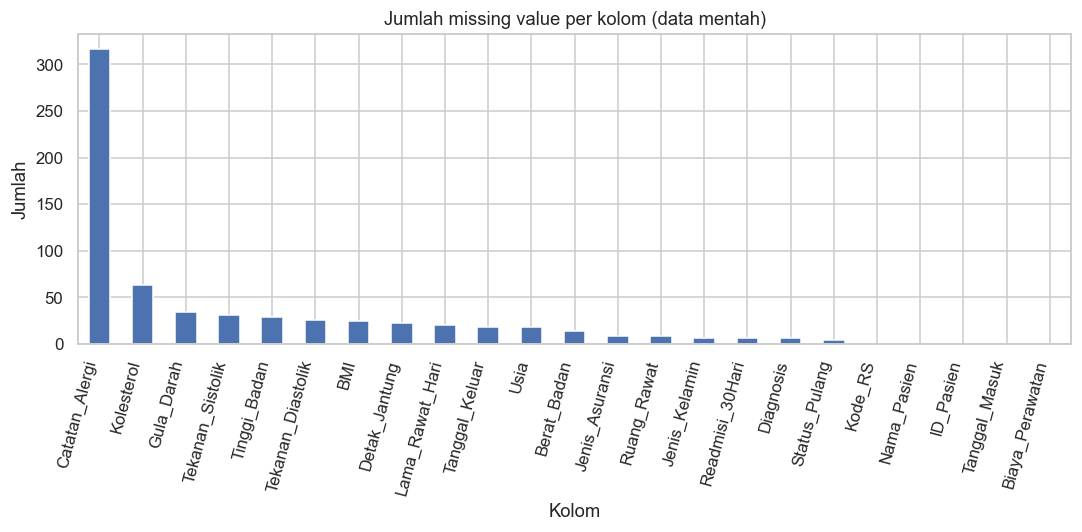

In [2]:
print("Jumlah baris dan kolom:", df.shape)

print("\nTipe data awal:")
display(df.dtypes.to_frame("tipe"))

miss = df.isna().sum().sort_values(ascending=False)
tabel_missing_awal = miss.to_frame("jumlah_kosong")
tabel_missing_awal["persen"] = (tabel_missing_awal["jumlah_kosong"] / len(df) * 100).round(1)
display(tabel_missing_awal)

print("Duplikat persis:", int(df.duplicated().sum()))
print("Baris dengan ID ganda:", int(df.duplicated(subset=["ID_Pasien"]).sum()))
print("Jumlah ID unik:", df["ID_Pasien"].nunique())

fig, ax = plt.subplots(figsize=(10, 5))
miss.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Jumlah missing value per kolom (data mentah)")
ax.set_ylabel("Jumlah")
ax.set_xlabel("Kolom")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.savefig("gambar/fig_missing.png", bbox_inches="tight")
plt.show()


In [3]:
for c in ["Jenis_Kelamin", "Diagnosis", "Jenis_Asuransi", "Ruang_Rawat",
          "Readmisi_30Hari", "Status_Pulang"]:
    print("\n--", c, "--")
    print(df[c].astype(str).value_counts(dropna=False).to_string())

print("\nContoh nilai numerik yang tidak seragam:")
for c in ["Usia", "Berat_Badan", "Tinggi_Badan", "Biaya_Perawatan"]:
    contoh = df[c].astype(str)[~df[c].astype(str).str.fullmatch(r"\d+(\.\d+)?")].dropna().unique()[:8]
    print(c, ":", contoh)



-- Jenis_Kelamin --
Jenis_Kelamin
Laki-laki    194
Perempuan    185
L              8
nan            6
laki-laki      6
Wanita         4
Pria           4
tidak ada      3
P              3
-              3
perempuan      2

-- Diagnosis --
Diagnosis
Diabetes Melitus     75
Hipertensi           71
Pneumonia            42
Stroke               35
Gagal Jantung        34
Demam Berdarah       26
DM                   11
Pneumonia            11
Gagal  Jantung       10
demam berdarah       10
PNEUMONIA            10
Diabetes Mellitus    10
hipertensi            9
DBD                   8
Hypertensi            7
nan                   6
gagal jantung         5
Hipertensi            5
pneumonia             5
diabetes mellitus     5
stroke                5
HT                    4
CHF                   4
STROKE                4
diabetes melitus      2
-                     2
tidak ada             2

-- Jenis_Asuransi --
Jenis_Asuransi
BPJS               212
Swasta              73
Umum                

### Daftar masalah data yang ditemukan

Angka pada daftar ini adalah kondisi data mentah; angka pada output kode adalah kondisi setelah pembersihan.

1. **Missing value numerik dan kategorik.** Usia 18, Tinggi_Badan 29, Kolesterol 63, Gula_Darah 34, dan lainnya. Terdapat nilai samaran `N/A`, `-`, `tidak ada`, serta `-999` pada Gula_Darah (11 baris).
2. **Duplikat.** 10 baris duplikat persis dan 18 ID berulang (36 baris); 8 di antaranya berisi berbeda.
3. **Kolom tidak relevan.** `Kode_RS` konstan (RS-01), `Catatan_Alergi` kosong 317/418 (75,8%), serta kolom identitas `ID_Pasien` dan `Nama_Pasien`.
4. **Kategori tidak konsisten.** Jenis_Kelamin memiliki 10 variasi, Diagnosis 26 variasi untuk 6 diagnosis, Asuransi 12 variasi, Ruang_Rawat 17 variasi, termasuk spasi ganda seperti `Gagal  Jantung`.
5. **Tipe dan satuan campuran.** Berat badan dalam kg, lb (`158 lb`), dan gram (`68900`); tinggi dalam cm dan meter (`1,57`); usia berbentuk `63 th`; biaya berbentuk `Rp 18.270.000`.
6. **Format tanggal campuran.** Tiga format: `2025-03-05`, `28/02/2025`, dan `27 Jun 2025`. Terdapat 5 tanggal keluar lebih awal daripada tanggal masuk.
7. **Lama rawat tidak konsisten.** 18 baris tidak sama dengan selisih tanggal (5 di antaranya akibat tanggal terbalik); setelah tanggal terbalik diperbaiki, tersisa 13 baris yang tetap tidak konsisten.
8. **Noise dan nilai mustahil.** Usia -3 dan 250; sistolik 900; gula darah -20 dan 780; kolesterol 620; detak jantung 0 dan 300.
9. **Logika medis dilanggar.** Tujuh baris pada data mentah (enam setelah duplikat dihapus) memiliki diastolik >= sistolik; empat tertangkap oleh batas rentang dan dua sisanya oleh aturan logika.
10. **Outlier ekstrem dan distribusi miring.** Biaya_Perawatan mencapai Rp 1.250.000.000 dengan skewness 19,37.
11. **Variabel turunan/redundan.** BMI seharusnya diturunkan dari berat dan tinggi; 9 dari 338 nilai BMI menyimpang lebih dari 3 poin.
12. **Missing tidak acak.** Kolesterol kosong 36,8% pada kelompok usia 65+ tetapi hanya 6,9-13,3% pada kelompok lain.
13. **Kelas target tidak seimbang.** Readmisi_30Hari: Ya 28 (6,7%) vs Tidak 378; Status_Pulang didominasi Sembuh (326; 78,0%).
14. **Skala antar variabel berbeda jauh.** Usia puluhan, sedangkan biaya ratusan juta rupiah.


## 2. Menghapus Atribut Tidak Relevan dan Menangani Duplikat

**Input:** data mentah yang masih mengandung penanda missing, kolom konstan, kolom mayoritas kosong, dan baris duplikat.  
**Proses:** menyeragamkan penanda missing, menghapus kolom tidak relevan, menghapus duplikat persis, lalu memilih satu baris untuk setiap ID ganda.  
**Output:** dataset 400 baris dengan ID unik dan 19 kolom fungsional.


In [4]:
# Hitung bukti sebelum dibersihkan
n_lb = int(df_raw["Berat_Badan"].astype(str).str.contains("lb", case=False).sum())
n_gram = int((pd.to_numeric(df_raw["Berat_Badan"], errors="coerce") > 1000).sum())
n_meter = int((pd.to_numeric(df_raw["Tinggi_Badan"], errors="coerce") < 3).sum())
n_rp = int(df_raw["Biaya_Perawatan"].astype(str).str.lower().str.startswith("rp").sum())
n_sentinel_999 = int(df_raw["Gula_Darah"].astype(str).str.strip().isin(["-999", "-999.0"]).sum())
n_tidak_ada = int(df_raw.apply(lambda col: col.astype(str).str.strip().str.lower() == "tidak ada").sum().sum())
n_exact_awal = int(df_raw.duplicated().sum())
n_id_awal = int(df_raw.duplicated(subset=["ID_Pasien"]).sum())

print("Berat dalam lb:", n_lb, "| gram:", n_gram, "| tinggi meter:", n_meter)
print("Biaya berformat Rp:", n_rp, "| sentinel -999:", n_sentinel_999, "| 'tidak ada':", n_tidak_ada)
print("Duplikat persis:", n_exact_awal, "| ID ganda:", n_id_awal)

# Samakan penanda missing
MISSING_TOKENS = {"", "nan", "NaN", "NA", "N/A", "n/a", "-", "-999", "-999.0",
                  "tidak ada", "Tidak ada", "TIDAK ADA", "null", "None", "?"}
for c in df.columns:
    s = df[c].astype(str).str.strip()
    df[c] = s.where(~s.isin(MISSING_TOKENS), np.nan)

# Hapus kolom tidak relevan
konstan = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
mayoritas_kosong = [c for c in df.columns if df[c].isna().mean() > 0.60]
identitas = ["Nama_Pasien"]

print("\nKolom konstan:", konstan)
print("Kolom >60% kosong:", mayoritas_kosong)
print("Kolom identitas yang dihapus dari pemodelan:", identitas)

df = df.drop(columns=konstan + mayoritas_kosong + identitas)
n_setelah_kolom = len(df)

# Duplikat persis
df = df.drop_duplicates()
n_setelah_exact = len(df)

# ID ganda: pilih baris paling lengkap; jika seri, pilih baris paling awal
df["_n_missing"] = df.isna().sum(axis=1)
df["_urutan"] = np.arange(len(df))
contoh_duplikat = (df[df.duplicated(subset=["ID_Pasien"], keep=False)]
                   .sort_values(["ID_Pasien", "_n_missing"])
                   [["ID_Pasien", "Jenis_Kelamin", "Usia", "Tekanan_Sistolik",
                     "Kolesterol", "Biaya_Perawatan"]])
display(contoh_duplikat.head(12))

df = (df.sort_values(["ID_Pasien", "_n_missing", "_urutan"])
        .drop_duplicates(subset=["ID_Pasien"], keep="first"))
df = df.drop(columns=["_n_missing", "_urutan"]).reset_index(drop=True)

n_exact_dihapus = n_setelah_kolom - n_setelah_exact
n_id_dihapus = n_setelah_exact - len(df)
print("Baris setelah kolom tidak relevan dihapus:", n_setelah_kolom)
print("Duplikat persis dihapus:", n_exact_dihapus)
print("Duplikat ID dihapus:", n_id_dihapus)
print("Ukuran akhir:", df.shape)

# ID hanya dipakai untuk deduplikasi
df = df.drop(columns=["ID_Pasien"])
print("Kolom setelah ID dihapus:", list(df.columns))


Berat dalam lb: 18 | gram: 9 | tinggi meter: 15
Biaya berformat Rp: 67 | sentinel -999: 11 | 'tidak ada': 17
Duplikat persis: 10 | ID ganda: 18

Kolom konstan: ['Kode_RS']
Kolom >60% kosong: ['Catatan_Alergi']
Kolom identitas yang dihapus dari pemodelan: ['Nama_Pasien']


,ID_Pasien,Jenis_Kelamin,Usia,Tekanan_Sistolik,Kolesterol,Biaya_Perawatan
154,PSN0051,Perempuan,52.0,127.0,227.0,1247000
90,PSN0051,Perempuan,52.0,130.0,NaN,1247000
124,PSN0118,Laki-laki,35.0,109.0,NaN,11314000
268,PSN0118,Laki-laki,35.0,107.0,NaN,11314000
76,PSN0192,Perempuan,61.0,143.0,NaN,8917000
416,PSN0192,Perempuan,61.0,145.0,NaN,8917000
106,PSN0196,Laki-laki,31.0,133.0,159.0,3962000
141,PSN0196,Laki-laki,31.0,133.0,NaN,3962000
171,PSN0219,Laki-laki,68.0,138.0,NaN,14912000
188,PSN0219,Laki-laki,68.0,137.0,NaN,14912000


Baris setelah kolom tidak relevan dihapus: 418
Duplikat persis dihapus: 10
Duplikat ID dihapus: 8
Ukuran akhir: (400, 20)
Kolom setelah ID dihapus: ['Jenis_Kelamin', 'Usia', 'Berat_Badan', 'Tinggi_Badan', 'BMI', 'Tekanan_Sistolik', 'Tekanan_Diastolik', 'Gula_Darah', 'Kolesterol', 'Detak_Jantung', 'Diagnosis', 'Jenis_Asuransi', 'Ruang_Rawat', 'Tanggal_Masuk', 'Tanggal_Keluar', 'Lama_Rawat_Hari', 'Biaya_Perawatan', 'Readmisi_30Hari', 'Status_Pulang']


**Aturan pemilihan baris untuk ID ganda:** baris dengan jumlah nilai kosong paling sedikit dipertahankan karena paling informatif. Jika jumlah nilai kosong sama, baris yang muncul lebih awal dipertahankan. Contoh: PSN0051 dipertahankan pada baris yang masih memiliki nilai Kolesterol; PSN0283 dipertahankan pada baris yang memiliki Kolesterol dan sistolik lebih lengkap.


## 3. Standarisasi Kategori dan Konversi Tipe/Satuan

**Input:** kategori dengan singkatan, typo, huruf besar-kecil, spasi ganda; angka dengan satuan campuran.  
**Proses:** memetakan kategori ke bentuk baku, mengekstrak angka, dan mengonversi satuan ke kg, cm, tahun, serta rupiah.  
**Output:** kategori baku dan kolom numerik bertipe angka.


In [5]:
def rapikan_teks(x):
    if pd.isna(x):
        return np.nan
    return re.sub(r"\s+", " ", str(x)).strip()

for c in ["Jenis_Kelamin", "Diagnosis", "Jenis_Asuransi", "Ruang_Rawat",
          "Readmisi_30Hari", "Status_Pulang"]:
    df[c] = df[c].map(rapikan_teks)

map_gender = {"laki-laki": "Laki-laki", "l": "Laki-laki", "pria": "Laki-laki",
              "perempuan": "Perempuan", "p": "Perempuan", "wanita": "Perempuan"}
df["Jenis_Kelamin"] = df["Jenis_Kelamin"].str.lower().map(map_gender)

map_dx = {"dm": "Diabetes Melitus", "diabetes melitus": "Diabetes Melitus",
          "diabetes mellitus": "Diabetes Melitus", "ht": "Hipertensi",
          "hipertensi": "Hipertensi", "hypertensi": "Hipertensi",
          "chf": "Gagal Jantung", "gagal jantung": "Gagal Jantung",
          "dbd": "Demam Berdarah", "demam berdarah": "Demam Berdarah",
          "pneumonia": "Pneumonia", "stroke": "Stroke"}
df["Diagnosis"] = df["Diagnosis"].str.lower().map(map_dx)

map_asuransi = {"bpjs": "BPJS", "bpjs kesehatan": "BPJS",
                "swasta": "Swasta", "asuransi swasta": "Swasta",
                "umum": "Umum", "mandiri/umum": "Umum"}
df["Jenis_Asuransi"] = df["Jenis_Asuransi"].str.lower().map(map_asuransi)

map_ruang = {"kelas 1": "Kelas 1", "kls 1": "Kelas 1", "i": "Kelas 1",
             "kelas 2": "Kelas 2", "kls 2": "Kelas 2", "ii": "Kelas 2",
             "kelas 3": "Kelas 3", "kls 3": "Kelas 3", "iii": "Kelas 3",
             "vip": "VIP"}
df["Ruang_Rawat"] = df["Ruang_Rawat"].str.lower().map(map_ruang)

df["Readmisi_30Hari"] = df["Readmisi_30Hari"].str.lower().map({"ya": "Ya", "tidak": "Tidak"})
df["Status_Pulang"] = df["Status_Pulang"].str.lower().map(
    {"sembuh": "Sembuh", "dirujuk": "Dirujuk", "meninggal": "Meninggal"})

def parse_usia(x):
    if pd.isna(x):
        return np.nan
    m = re.search(r"-?\d+", str(x))
    return float(m.group()) if m else np.nan

def parse_berat(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if "lb" in s:
        v = pd.to_numeric(s.replace("lb", "").strip(), errors="coerce")
        return v * 0.45359237
    v = pd.to_numeric(s, errors="coerce")
    if pd.notna(v) and v > 1000:
        v = v / 1000.0
    return v

def parse_tinggi(x):
    if pd.isna(x):
        return np.nan
    v = pd.to_numeric(str(x).strip(), errors="coerce")
    if pd.notna(v) and v < 3:
        v = v * 100.0
    return v

def parse_biaya(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower().replace("rp", "").replace(" ", "")
    s = s.replace(".", "").replace(",", ".")
    return pd.to_numeric(s, errors="coerce")

df["Usia"] = df["Usia"].map(parse_usia)
df["Berat_Badan"] = df["Berat_Badan"].map(parse_berat)
df["Tinggi_Badan"] = df["Tinggi_Badan"].map(parse_tinggi)
df["Biaya_Perawatan"] = df["Biaya_Perawatan"].map(parse_biaya)
for c in ["BMI", "Tekanan_Sistolik", "Tekanan_Diastolik", "Gula_Darah",
          "Kolesterol", "Detak_Jantung", "Lama_Rawat_Hari"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

for c in ["Jenis_Kelamin", "Diagnosis", "Jenis_Asuransi", "Ruang_Rawat",
          "Readmisi_30Hari", "Status_Pulang"]:
    print("\n--", c, "--")
    print(df[c].value_counts(dropna=False).to_string())

print("\nRentang hasil konversi:")
print("Usia:", df["Usia"].min(), "-", df["Usia"].max())
print("Berat (kg):", round(df["Berat_Badan"].min(), 1), "-", round(df["Berat_Badan"].max(), 1))
print("Tinggi (cm):", round(df["Tinggi_Badan"].min(), 1), "-", round(df["Tinggi_Badan"].max(), 1))
print("Biaya (Rp):", int(df["Biaya_Perawatan"].min()), "-", int(df["Biaya_Perawatan"].max()))



-- Jenis_Kelamin --
Jenis_Kelamin
Laki-laki    202
Perempuan    186
NaN           12

-- Diagnosis --
Diagnosis
Diabetes Melitus    98
Hipertensi          91
Pneumonia           66
Gagal Jantung       51
Stroke              42
Demam Berdarah      42
NaN                 10

-- Jenis_Asuransi --
Jenis_Asuransi
BPJS      247
Swasta     86
Umum       51
NaN        16

-- Ruang_Rawat --
Ruang_Rawat
Kelas 3    163
Kelas 2    117
Kelas 1     74
VIP         32
NaN         14

-- Readmisi_30Hari --
Readmisi_30Hari
Tidak    361
Ya        27
NaN       12

-- Status_Pulang --
Status_Pulang
Sembuh       312
Dirujuk       44
Meninggal     36
NaN            8

Rentang hasil konversi:
Usia: -3.0 - 250.0
Berat (kg): 36.0 - 108.8
Tinggi (cm): 140.0 - 185.6
Biaya (Rp): 882000 - 1250000000


Satuan berat diseragamkan ke kilogram: nilai bertanda `lb` dikalikan 0,45359237 dan nilai ribuan (gram) dibagi 1.000. Tinggi diseragamkan ke sentimeter: nilai di bawah 3 dianggap meter lalu dikalikan 100. Biaya dibersihkan dari `Rp`, titik ribuan, dan spasi.


## 4. Parsing Tanggal, Perbaikan Tanggal Terbalik, dan Validasi Lama Rawat

**Input:** tanggal dengan tiga format dan Lama_Rawat_Hari yang sebagian tidak sesuai.  
**Proses:** mem-parsing tanggal, menukar tanggal terbalik, mengisi tanggal keluar yang kosong, lalu menghitung ulang lama rawat.  
**Output:** tanggal bertipe datetime, lama rawat konsisten, dan tidak ada tanggal kosong.


In [6]:
def parse_tanggal(x):
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d %b %Y", "%d %B %Y"):
        try:
            return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError):
            pass
    return pd.NaT

df["Tanggal_Masuk"] = df["Tanggal_Masuk"].map(parse_tanggal)
df["Tanggal_Keluar"] = df["Tanggal_Keluar"].map(parse_tanggal)

terbalik = df["Tanggal_Keluar"] < df["Tanggal_Masuk"]
n_terbalik = int(terbalik.sum())
print("Tanggal keluar lebih awal dari tanggal masuk:", n_terbalik)
display(df.loc[terbalik, ["Tanggal_Masuk", "Tanggal_Keluar", "Lama_Rawat_Hari"]])

# Tukar tanggal yang terbalik
tmp = df.loc[terbalik, "Tanggal_Masuk"].copy()
df.loc[terbalik, "Tanggal_Masuk"] = df.loc[terbalik, "Tanggal_Keluar"]
df.loc[terbalik, "Tanggal_Keluar"] = tmp

# Isi tanggal keluar yang kosong dari tanggal masuk + lama rawat
mask_keluar = (df["Tanggal_Keluar"].isna() & df["Tanggal_Masuk"].notna()
               & df["Lama_Rawat_Hari"].notna())
df.loc[mask_keluar, "Tanggal_Keluar"] = (
    df.loc[mask_keluar, "Tanggal_Masuk"]
    + pd.to_timedelta(df.loc[mask_keluar, "Lama_Rawat_Hari"], unit="D"))

selisih = (df["Tanggal_Keluar"] - df["Tanggal_Masuk"]).dt.days

# Lama rawat yang tidak sesuai dengan selisih tanggal
tidak_konsisten = selisih.notna() & df["Lama_Rawat_Hari"].notna() & (selisih != df["Lama_Rawat_Hari"])
n_lama_mismatch = int(tidak_konsisten.sum())
print("Lama rawat tidak konsisten dengan selisih tanggal:", n_lama_mismatch)

# Lengkapi lama rawat dan tanggal keluar
df["Lama_Rawat_Hari"] = df["Lama_Rawat_Hari"].fillna(selisih)
if df["Lama_Rawat_Hari"].isna().any():
    df["Lama_Rawat_Hari"] = df["Lama_Rawat_Hari"].fillna(df["Lama_Rawat_Hari"].median())
mask_keluar2 = df["Tanggal_Keluar"].isna() & df["Tanggal_Masuk"].notna()
df.loc[mask_keluar2, "Tanggal_Keluar"] = (
    df.loc[mask_keluar2, "Tanggal_Masuk"]
    + pd.to_timedelta(df.loc[mask_keluar2, "Lama_Rawat_Hari"], unit="D"))

# Lama rawat final mengikuti selisih tanggal yang sudah diperbaiki
df["Lama_Rawat_Hari"] = (df["Tanggal_Keluar"] - df["Tanggal_Masuk"]).dt.days
print("Sisa tanggal kosong:", int(df["Tanggal_Masuk"].isna().sum() + df["Tanggal_Keluar"].isna().sum()))
print("Rentang lama rawat:", int(df["Lama_Rawat_Hari"].min()), "-", int(df["Lama_Rawat_Hari"].max()), "hari")


Tanggal keluar lebih awal dari tanggal masuk: 5


,Tanggal_Masuk,Tanggal_Keluar,Lama_Rawat_Hari
91,2025-07-24,2025-07-23,1.0
118,2025-07-18,2025-07-10,8.0
161,2025-08-25,2025-08-15,10.0
299,2025-08-09,2025-08-06,3.0
399,2025-03-24,2025-03-23,1.0


Lama rawat tidak konsisten dengan selisih tanggal: 13
Sisa tanggal kosong: 0
Rentang lama rawat: 1 - 39 hari


Tanggal terbalik ditukar karena lama rawat yang tercatat selalu sama dengan selisih absolut kedua tanggal, sehingga tertukarnya tanggal masuk dan keluar adalah penyebab yang paling masuk akal. Setelah itu, Lama_Rawat_Hari dihitung ulang dari selisih tanggal agar konsisten.


## 5. Menangani Noise, Nilai Samaran, Pelanggaran Logika Medis, dan BMI

**Input:** nilai di luar rentang wajar dan pasangan tekanan darah yang tidak masuk akal.  
**Proses:** mengubah nilai mustahil menjadi missing, memperbaiki logika tekanan darah, lalu menghitung ulang BMI.  
**Output:** nilai fisiologis berada pada rentang wajar dan BMI konsisten dengan berat serta tinggi.


In [7]:
num_cols = ["Usia", "Berat_Badan", "Tinggi_Badan", "BMI", "Tekanan_Sistolik",
            "Tekanan_Diastolik", "Gula_Darah", "Kolesterol", "Detak_Jantung",
            "Lama_Rawat_Hari", "Biaya_Perawatan"]

batas = {"Usia": (1, 110), "Berat_Badan": (30, 250), "Tinggi_Badan": (100, 250),
         "Tekanan_Sistolik": (70, 250), "Tekanan_Diastolik": (40, 150),
         "Gula_Darah": (40, 600), "Kolesterol": (50, 500), "Detak_Jantung": (30, 220)}
for c, (lo, hi) in batas.items():
    salah = (df[c] < lo) | (df[c] > hi)
    print(f"{c}: {int(salah.sum())} nilai di luar [{lo}, {hi}] -> missing")
    df.loc[salah, c] = np.nan

logika = df["Tekanan_Diastolik"] >= df["Tekanan_Sistolik"]
print("Diastolik >= Sistolik:", int(logika.sum()))
df.loc[logika, "Tekanan_Diastolik"] = np.nan

df["BMI"] = (df["Berat_Badan"] / (df["Tinggi_Badan"] / 100) ** 2).round(2)

print("\nMissing setelah pembersihan noise:")
print(df[num_cols].isna().sum().to_string())


Usia: 2 nilai di luar [1, 110] -> missing
Berat_Badan: 0 nilai di luar [30, 250] -> missing
Tinggi_Badan: 0 nilai di luar [100, 250] -> missing
Tekanan_Sistolik: 1 nilai di luar [70, 250] -> missing
Tekanan_Diastolik: 4 nilai di luar [40, 150] -> missing
Gula_Darah: 2 nilai di luar [40, 600] -> missing
Kolesterol: 1 nilai di luar [50, 500] -> missing
Detak_Jantung: 2 nilai di luar [30, 220] -> missing
Diastolik >= Sistolik: 2

Missing setelah pembersihan noise:
Usia                 20
Berat_Badan          14
Tinggi_Badan         28
BMI                  41
Tekanan_Sistolik     31
Tekanan_Diastolik    32
Gula_Darah           46
Kolesterol           55
Detak_Jantung        24
Lama_Rawat_Hari       0
Biaya_Perawatan       0


Aturan yang dipakai: nilai di luar rentang fisiologis dianggap noise dan diubah menjadi missing agar tidak mengganggu statistik imputasi. Jika diastolik >= sistolik, nilai diastolik dianggap salah catat dan dikosongkan, sedangkan sistolik dipertahankan karena umumnya lebih andal. BMI tidak dipertahankan dari file asal, tetapi dihitung ulang dari berat dan tinggi.


## 6. Menangani Missing Value dengan Statistik Deskriptif

**Input:** missing value pada variabel numerik dan kategorik.  
**Proses:** menghitung mean, median, modus, skewness, lalu memilih metode imputasi; Kolesterol diimputasi per kelompok usia.  
**Output:** dataset tanpa missing value.


In [8]:
def hitung_modus(s):
    m = s.mode(dropna=True)
    return m.iloc[0] if len(m) else np.nan

baris = []
for c in num_cols:
    s = df[c]
    n = int(s.isna().sum())
    sk = float(s.skew())
    if n == 0:
        metode, nilai = "tidak perlu", np.nan
    elif c == "BMI":
        metode, nilai = "dihitung ulang", np.nan
    elif c == "Kolesterol":
        metode, nilai = "median per kelompok usia", np.nan
    elif abs(sk) < 0.5:
        metode, nilai = "mean", s.mean()
    else:
        metode, nilai = "median", s.median()
    baris.append({"Variabel": c, "Jumlah_Missing": n,
                  "Mean": round(s.mean(), 2), "Median": round(s.median(), 2),
                  "Modus": round(hitung_modus(s), 2), "Skewness": round(sk, 3),
                  "Metode": metode, "Nilai_Imputasi": round(nilai, 2) if pd.notna(nilai) else np.nan})

stat_missing = pd.DataFrame(baris)
display(stat_missing)

# Statistik missing kategorik
cat_cols = ["Jenis_Kelamin", "Diagnosis", "Jenis_Asuransi", "Ruang_Rawat",
            "Readmisi_30Hari", "Status_Pulang"]
cat_missing = pd.DataFrame({
    "Variabel": cat_cols,
    "Jumlah_Missing": [int(df[c].isna().sum()) for c in cat_cols],
    "Modus": [df[c].mode(dropna=True).iloc[0] for c in cat_cols],
})
display(cat_missing)


,Variabel,Jumlah_Missing,Mean,Median,Modus,Skewness,Metode,Nilai_Imputasi
0,Usia,20,52.01,51.00,51.00,-0.205,mean,52.01
1,Berat_Badan,14,64.86,63.80,57.30,0.456,mean,64.86
2,Tinggi_Badan,28,162.24,162.15,160.90,-0.039,mean,162.24
3,BMI,41,24.57,24.56,21.22,-0.001,dihitung ulang,NaN
4,Tekanan_Sistolik,31,134.34,133.00,128.00,0.182,mean,134.34
5,Tekanan_Diastolik,32,81.76,82.00,82.00,0.099,mean,81.76
6,Gula_Darah,46,137.02,114.10,103.40,1.159,median,114.10
7,Kolesterol,55,189.72,190.00,192.00,-0.163,median per kelompok usia,NaN
8,Detak_Jantung,24,79.06,79.00,83.00,0.031,mean,79.06
9,Lama_Rawat_Hari,0,6.60,5.00,3.00,2.212,tidak perlu,NaN


,Variabel,Jumlah_Missing,Modus
0,Jenis_Kelamin,12,Laki-laki
1,Diagnosis,10,Diabetes Melitus
2,Jenis_Asuransi,16,BPJS
3,Ruang_Rawat,14,Kelas 3
4,Readmisi_30Hari,12,Tidak
5,Status_Pulang,8,Sembuh


,Kelompok_Usia,Jumlah,Missing,Median,Missing_Persen
0,<18,13,1,165.5,7.7
1,18-34,42,4,178.5,9.5
2,35-49,110,11,184.0,10.0
3,50-64,144,5,195.0,3.5
4,65+,91,34,212.0,37.4


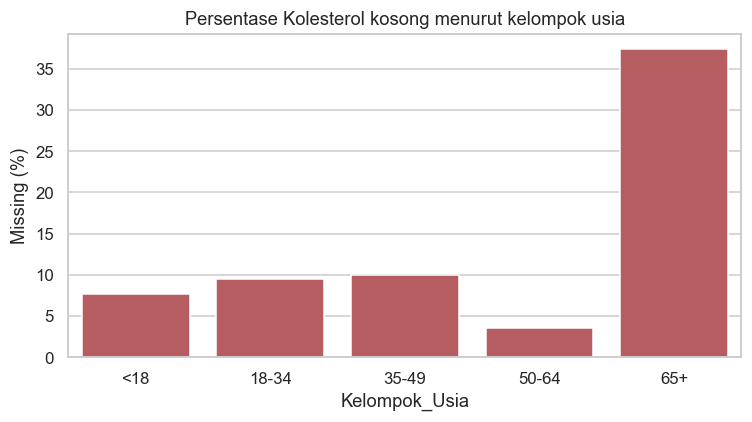

In [9]:
# Kolesterol: cek pola missing menurut kelompok usia
# Imputasi Usia lebih dulu agar seluruh baris masuk kelompok usia yang benar
_sk = df["Usia"].skew()
df["Usia"] = df["Usia"].fillna(df["Usia"].mean() if abs(_sk) < 0.5 else df["Usia"].median())
_kelompok = pd.cut(df["Usia"], bins=[0, 17, 34, 49, 64, 120],
                   labels=["<18", "18-34", "35-49", "50-64", "65+"])

tabel_kol = pd.DataFrame({"Kelompok_Usia": _kelompok, "Kolesterol": df["Kolesterol"]})
tabel_kol = tabel_kol.groupby("Kelompok_Usia", observed=False)["Kolesterol"].agg(
    Jumlah="size", Missing=lambda s: int(s.isna().sum()), Median="median").reset_index()
tabel_kol["Missing_Persen"] = (tabel_kol["Missing"] / tabel_kol["Jumlah"] * 100).round(1)
display(tabel_kol)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=tabel_kol, x="Kelompok_Usia", y="Missing_Persen", ax=ax, color="#C44E52")
ax.set_title("Persentase Kolesterol kosong menurut kelompok usia")
ax.set_ylabel("Missing (%)")
plt.tight_layout()
plt.savefig("gambar/fig_kolesterol.png", bbox_inches="tight")
plt.show()


In [10]:
# Imputasi numerik
def isi_numerik(c):
    s = df[c]
    if s.isna().sum() == 0:
        return
    sk = s.skew()
    nilai = s.mean() if abs(sk) < 0.5 else s.median()
    df[c] = s.fillna(nilai)

# Urutan penting: usia dulu, lalu berat/tinggi, lalu BMI, lalu Kolesterol per kelompok
isi_numerik("Usia")
isi_numerik("Berat_Badan")
isi_numerik("Tinggi_Badan")
df["BMI"] = (df["Berat_Badan"] / (df["Tinggi_Badan"] / 100) ** 2).round(2)

_kelompok = pd.cut(df["Usia"], bins=[0, 17, 34, 49, 64, 120],
                   labels=["<18", "18-34", "35-49", "50-64", "65+"])
df["Kolesterol"] = df["Kolesterol"].fillna(
    df.groupby(_kelompok, observed=False)["Kolesterol"].transform("median"))

for c in ["Tekanan_Sistolik", "Tekanan_Diastolik", "Gula_Darah", "Detak_Jantung"]:
    isi_numerik(c)

# Imputasi kategorik dengan modus
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode(dropna=True).iloc[0])

print("Total missing setelah imputasi:", int(df.isna().sum().sum()))
assert df.isna().sum().sum() == 0
print("Ukuran data setelah pembersihan:", df.shape)


Total missing setelah imputasi: 0
Ukuran data setelah pembersihan: (400, 19)


**Mengapa imputasi Kolesterol per kelompok usia lebih tepat?** Pola missingnya tidak acak. Pada data mentah, Kolesterol kosong 36,8% pada kelompok 65+ dan 6,9-13,3% pada kelompok lain; setelah deduplikasi dan imputasi usia, angkanya menjadi 37,4% berbanding 3,5-10,0%. Kadar kolesterol juga cenderung meningkat seiring usia. Jika dipakai median global, nilai imputasi akan terlalu rendah untuk pasien lansia dan terlalu tinggi untuk pasien muda. Median per kelompok usia mempertahankan perbedaan alami tersebut dan mengurangi bias.

## 7. Deteksi Outlier dengan IQR, Transformasi Log, dan Capping

**Input:** Biaya_Perawatan dengan ekor distribusi sangat panjang.  
**Proses:** menghitung batas IQR, memeriksa outlier pada semua variabel numerik, melakukan transformasi log1p pada biaya, lalu capping pada skala log.  
**Output:** distribusi biaya lebih simetris dan outlier ekstrem tidak lagi mendominasi.


In [11]:
def info_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    jumlah = int(((s < lo) | (s > hi)).sum())
    return q1, q3, iqr, lo, hi, jumlah

baris = []
for c in num_cols:
    q1, q3, iqr, lo, hi, jumlah = info_iqr(df[c])
    baris.append({"Variabel": c, "Q1": round(q1, 2), "Q3": round(q3, 2),
                  "IQR": round(iqr, 2), "Batas_Bawah": round(lo, 2),
                  "Batas_Atas": round(hi, 2), "Jumlah_Outlier": jumlah})
outlier_tbl = pd.DataFrame(baris)
display(outlier_tbl)


,Variabel,Q1,Q3,IQR,Batas_Bawah,Batas_Atas,Jumlah_Outlier
0,Usia,42.00,63.00,21.00,10.50,94.50,3
1,Berat_Badan,55.88,73.12,17.25,30.00,99.00,3
2,Tinggi_Badan,156.30,168.30,12.00,138.30,186.30,0
3,BMI,21.61,27.84,6.23,12.27,37.17,0
4,Tekanan_Sistolik,123.75,146.00,22.25,90.38,179.38,5
5,Tekanan_Diastolik,75.00,88.00,13.00,55.50,107.50,5
6,Gula_Darah,106.00,133.22,27.22,65.16,174.06,83
7,Kolesterol,173.00,212.00,39.00,114.50,270.50,5
8,Detak_Jantung,72.00,86.00,14.00,51.00,107.00,2
9,Lama_Rawat_Hari,3.00,8.00,5.00,-4.50,15.50,20


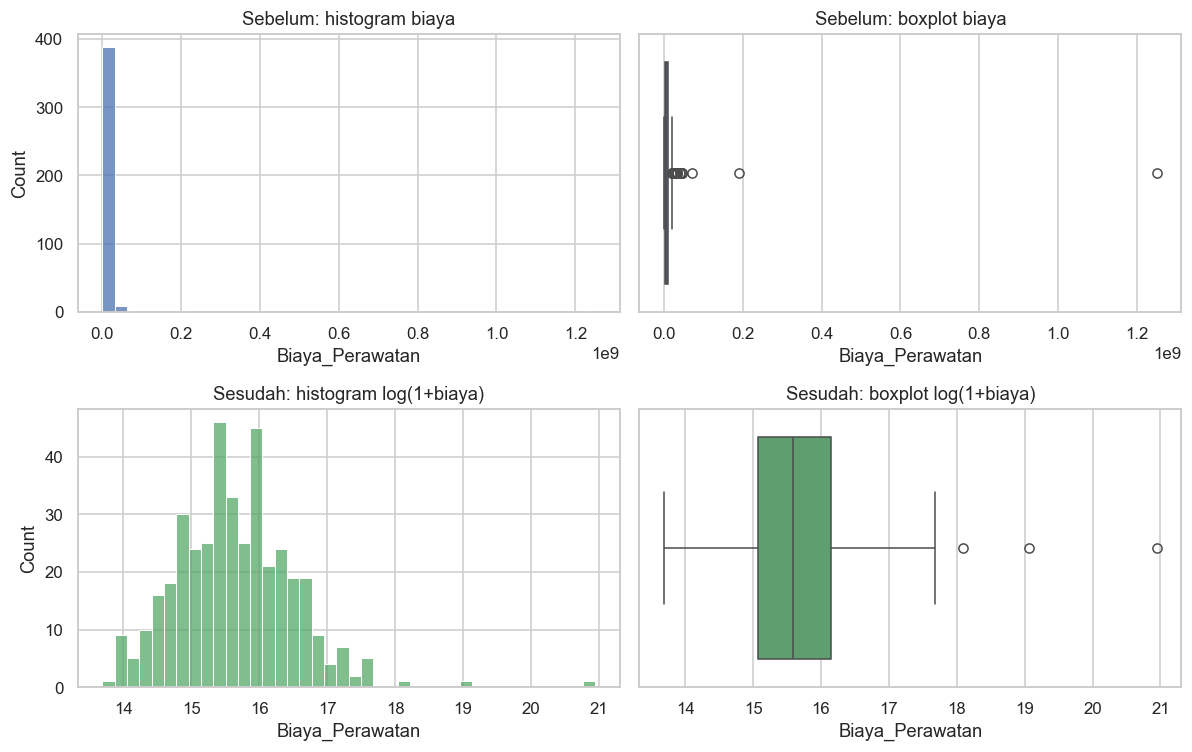

Jumlah nilai yang di-capping: 3
Skewness sebelum: 18.954 | sesudah: 2.679

Statistik biaya sebelum capping:
count    4.000000e+02
mean     1.200012e+07
std      6.324383e+07
min      8.820000e+05
25%      3.510750e+06
50%      5.866500e+06
75%      1.032725e+07
99%      4.725079e+07
max      1.250000e+09

Statistik biaya setelah capping:
count         400.00
mean      8607706.16
std       8351237.78
min        882000.00
25%       3510750.00
50%       5866500.00
75%      10327250.00
99%      47250790.00
max      52104155.31


In [12]:
biaya_sebelum = df["Biaya_Perawatan"].describe(percentiles=[0.25, 0.5, 0.75, 0.99])
skew_sebelum = float(df["Biaya_Perawatan"].skew())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(df["Biaya_Perawatan"], bins=40, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Sebelum: histogram biaya")
sns.boxplot(x=df["Biaya_Perawatan"], ax=axes[0, 1], color="#4C72B0")
axes[0, 1].set_title("Sebelum: boxplot biaya")

log_biaya = np.log1p(df["Biaya_Perawatan"])
sns.histplot(log_biaya, bins=40, ax=axes[1, 0], color="#55A868")
axes[1, 0].set_title("Sesudah: histogram log(1+biaya)")
sns.boxplot(x=log_biaya, ax=axes[1, 1], color="#55A868")
axes[1, 1].set_title("Sesudah: boxplot log(1+biaya)")
plt.tight_layout()
plt.savefig("gambar/fig_biaya.png", bbox_inches="tight")
plt.show()

# Capping pada skala log memakai batas IQR
q1, q3 = log_biaya.quantile(0.25), log_biaya.quantile(0.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_cap = int(((log_biaya < lo) | (log_biaya > hi)).sum())
log_cap = log_biaya.clip(lo, hi)

df["Biaya_Log"] = log_cap
df["Biaya_Perawatan"] = np.expm1(log_cap)

biaya_sesudah = df["Biaya_Perawatan"].describe(percentiles=[0.25, 0.5, 0.75, 0.99])
skew_sesudah = float(df["Biaya_Perawatan"].skew())
print("Jumlah nilai yang di-capping:", n_cap)
print("Skewness sebelum:", round(skew_sebelum, 3), "| sesudah:", round(skew_sesudah, 3))
print("\nStatistik biaya sebelum capping:")
print(biaya_sebelum.round(2).to_string())
print("\nStatistik biaya setelah capping:")
print(biaya_sesudah.round(2).to_string())


Batas IQR pada biaya mentah akan memotong terlalu banyak nilai sah karena distribusinya sangat miring. Karena itu, deteksi IQR tetap dilakukan pada biaya mentah untuk menunjukkan jumlah outlier, tetapi capping dilakukan setelah transformasi `log1p`. Pada skala log, distribusi mendekati normal sehingga batas IQR lebih stabil dan hanya nilai ekstrem yang dipotong.


## 8. Encoding Variabel Kategorik dan Proporsi Kelas Target

**Input:** kategori nominal dan ordinal.  
**Proses:** memberi kode ordinal pada Ruang_Rawat, one-hot encoding pada kategori nominal, dan menghitung proporsi kelas target.  
**Output:** matriks fitur numerik siap dianalisis.


In [13]:
# Ordinal: semakin tinggi fasilitas, semakin besar kodenya
map_ruang_ord = {"Kelas 3": 1, "Kelas 2": 2, "Kelas 1": 3, "VIP": 4}
df["Ruang_Rawat_Ordinal"] = df["Ruang_Rawat"].map(map_ruang_ord)

# Target
df["Readmisi"] = df["Readmisi_30Hari"].map({"Ya": 1, "Tidak": 0})
df["Status_Pulang_Code"] = df["Status_Pulang"].map({"Sembuh": 0, "Dirujuk": 1, "Meninggal": 2})

# One-hot untuk kategori nominal
nominal = ["Jenis_Kelamin", "Diagnosis", "Jenis_Asuransi"]
df = pd.get_dummies(df, columns=nominal, drop_first=True, dtype=int)

prop_readmisi = (df["Readmisi_30Hari"].value_counts(normalize=True) * 100).round(2)
prop_status = (df["Status_Pulang"].value_counts(normalize=True) * 100).round(2)

print("Proporsi Readmisi_30Hari (%):")
print(prop_readmisi.to_string())
print("\nProporsi Status_Pulang (%):")
print(prop_status.to_string())
print("\nRasio kelas Readmisi (Tidak : Ya):",
      round(df["Readmisi"].value_counts()[0] / df["Readmisi"].value_counts()[1], 2), ": 1")
print("\nUkuran setelah encoding:", df.shape)
print("Contoh kolom hasil encoding:", [c for c in df.columns if "_" in c and c.startswith(("Jenis_Kelamin_", "Diagnosis_", "Jenis_Asuransi_"))][:8])


Proporsi Readmisi_30Hari (%):
Readmisi_30Hari
Tidak    93.25
Ya        6.75

Proporsi Status_Pulang (%):
Status_Pulang
Sembuh       80.0
Dirujuk      11.0
Meninggal     9.0

Rasio kelas Readmisi (Tidak : Ya): 13.81 : 1

Ukuran setelah encoding: (400, 28)
Contoh kolom hasil encoding: ['Jenis_Kelamin_Perempuan', 'Diagnosis_Diabetes Melitus', 'Diagnosis_Gagal Jantung', 'Diagnosis_Hipertensi', 'Diagnosis_Pneumonia', 'Diagnosis_Stroke', 'Jenis_Asuransi_Swasta', 'Jenis_Asuransi_Umum']


Ruang_Rawat diberi kode ordinal 1-4 karena memiliki urutan tingkat fasilitas (Kelas 3 < Kelas 2 < Kelas 1 < VIP). Kategori nominal tidak memiliki urutan, sehingga memakai one-hot encoding; opsi `drop_first=True` dipakai untuk menghindari dummy trap (multikolinearitas sempurna).


## 9. Matriks Korelasi dan Multikolinearitas

**Input:** fitur numerik dan target biner Readmisi.  
**Proses:** menghitung korelasi Pearson dan menampilkan pasangan dengan korelasi kuat.  
**Output:** daftar pasangan fitur yang berkorelasi kuat.


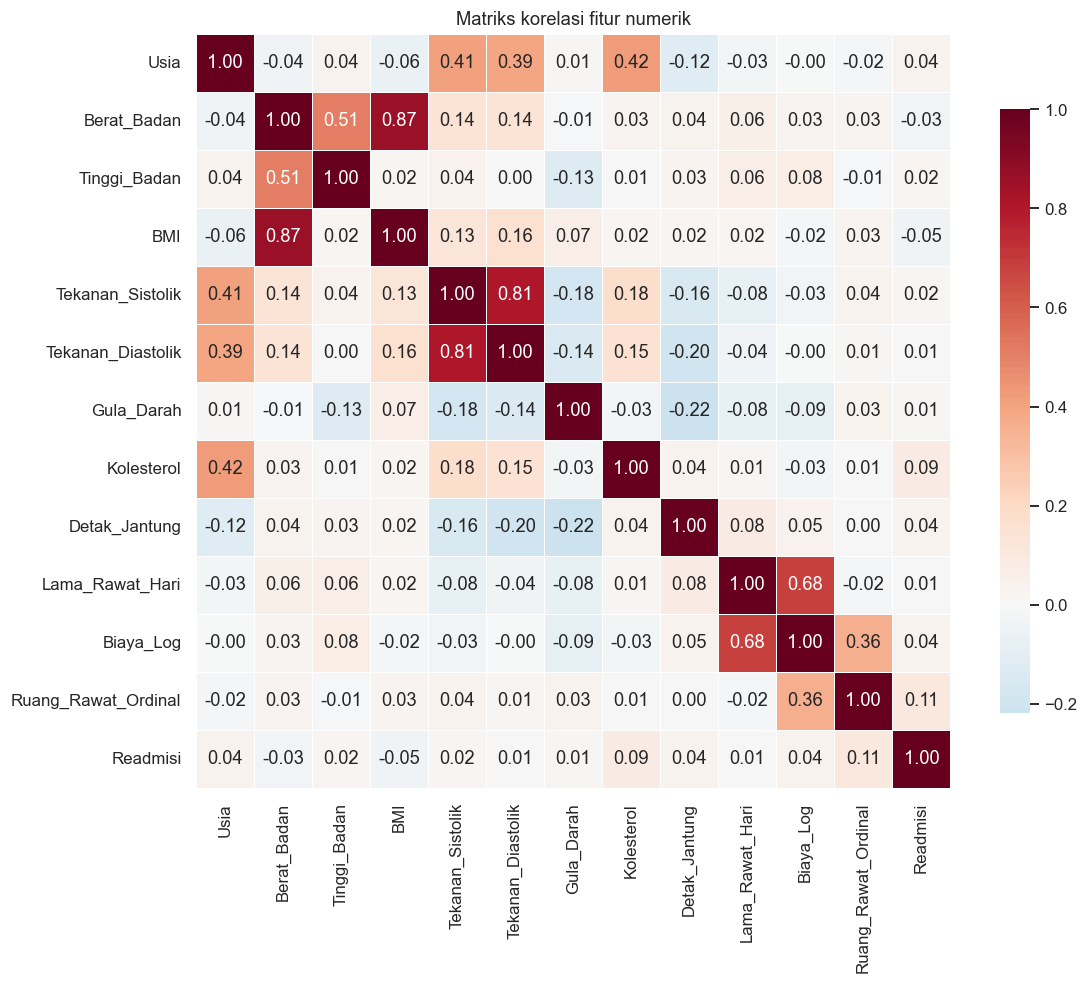

Sepuluh pasangan dengan korelasi absolut terbesar:


,Variabel_1,Variabel_2,Korelasi
0,Berat_Badan,BMI,0.866
1,Tekanan_Sistolik,Tekanan_Diastolik,0.809
2,Lama_Rawat_Hari,Biaya_Log,0.681
3,Berat_Badan,Tinggi_Badan,0.506
4,Usia,Kolesterol,0.424
5,Usia,Tekanan_Sistolik,0.413
6,Usia,Tekanan_Diastolik,0.395
7,Biaya_Log,Ruang_Rawat_Ordinal,0.359
8,Gula_Darah,Detak_Jantung,-0.217
9,Tekanan_Diastolik,Detak_Jantung,-0.199



Pasangan dengan |r| >= 0,7:


,Variabel_1,Variabel_2,Korelasi
0,Berat_Badan,BMI,0.866
1,Tekanan_Sistolik,Tekanan_Diastolik,0.809


In [14]:
fitur_korelasi = ["Usia", "Berat_Badan", "Tinggi_Badan", "BMI", "Tekanan_Sistolik",
                   "Tekanan_Diastolik", "Gula_Darah", "Kolesterol", "Detak_Jantung",
                   "Lama_Rawat_Hari", "Biaya_Log", "Ruang_Rawat_Ordinal", "Readmisi"]
corr = df[fitur_korelasi].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matriks korelasi fitur numerik")
plt.tight_layout()
plt.savefig("gambar/fig_korelasi.png", bbox_inches="tight")
plt.show()

pasangan = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pasangan.columns = ["Variabel_1", "Variabel_2", "Korelasi"]
pasangan["Abs"] = pasangan["Korelasi"].abs()
pasangan = pasangan.sort_values("Abs", ascending=False).drop(columns="Abs").reset_index(drop=True)
print("Sepuluh pasangan dengan korelasi absolut terbesar:")
display(pasangan.head(10).round(3))

kuat = pasangan[(pasangan["Korelasi"].abs() >= 0.7)].copy()
print("\nPasangan dengan |r| >= 0,7:")
display(kuat.round(3))


## 10. Data Transformation: Decimal Scaling, Min-Max, Standardization, Robust Scaling, dan Binning

**Input:** Usia dan Biaya_Perawatan dengan skala sangat berbeda.  
**Proses:** menerapkan empat metode scaling secara manual dan dengan library, lalu membandingkan statistiknya; Usia juga dikelompokkan menjadi bin.  
**Output:** tabel perbandingan scaling dan distribusi kelompok usia.


,Variabel,Metode,Mean,Std,Min,Max,Median,IQR
0,Usia,Decimal Scaling (manual),0.520,0.165,0.030,0.940,0.520,0.210
1,Usia,Min-Max (manual),0.539,0.181,0.000,1.000,0.539,0.231
2,Usia,Z-Score (manual),-0.000,1.001,-2.979,2.552,0.000,1.276
3,Usia,Robust (manual),-0.000,0.785,-2.334,1.999,0.000,1.000
4,Usia,Min-Max (sklearn),0.539,0.181,0.000,1.000,0.539,0.231
5,Usia,Standardization (sklearn),-0.000,1.001,-2.979,2.552,0.000,1.276
6,Usia,Robust (sklearn),-0.000,0.785,-2.334,1.999,0.000,1.000
7,Biaya_Perawatan,Decimal Scaling (manual),0.086,0.084,0.009,0.521,0.059,0.068
8,Biaya_Perawatan,Min-Max (manual),0.151,0.163,0.000,1.000,0.097,0.133
9,Biaya_Perawatan,Z-Score (manual),-0.000,1.001,-0.926,5.215,-0.329,0.817


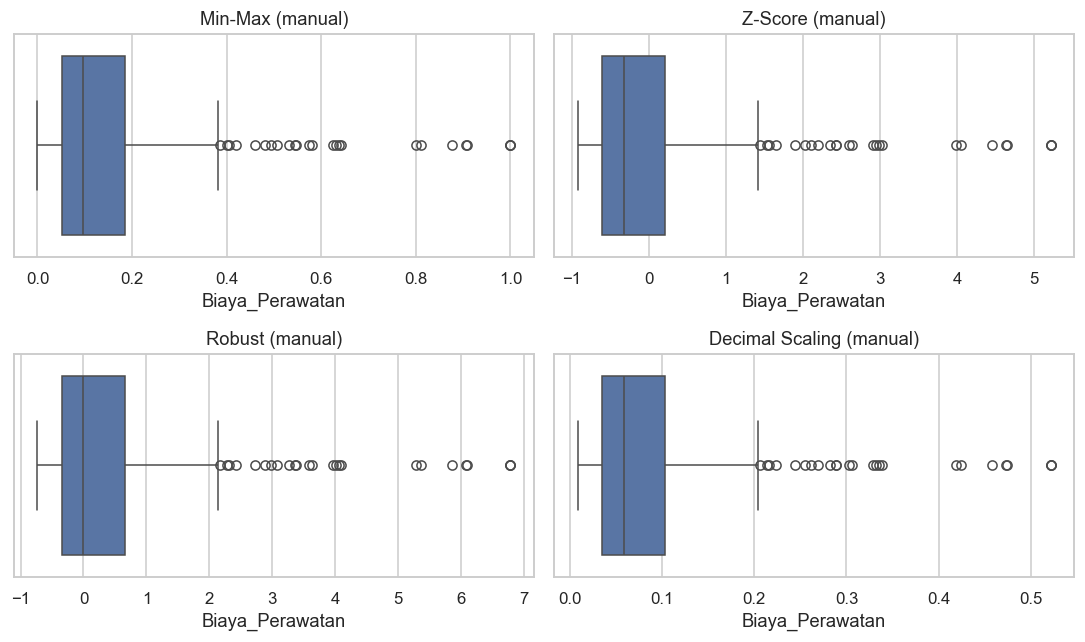


Distribusi kelompok usia:
Kelompok_Usia
<18       13
18-34     42
35-49    110
50-64    144
65+       91


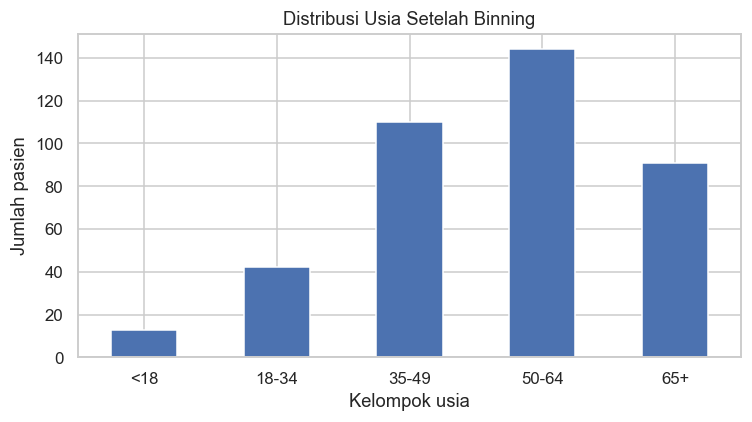

In [15]:
def decimal_manual(x):
    k = int(np.ceil(np.log10(np.nanmax(np.abs(x)))))
    return x / (10 ** k), k

def minmax_manual(x):
    return (x - x.min()) / (x.max() - x.min())

def zscore_manual(x):
    return (x - x.mean()) / x.std(ddof=0)

def robust_manual(x):
    return (x - x.median()) / (x.quantile(0.75) - x.quantile(0.25))

hasil = []
for nama in ["Usia", "Biaya_Perawatan"]:
    x = df[nama].astype(float)
    dec, k = decimal_manual(x)
    varian = {
        "Decimal Scaling (manual)": dec,
        "Min-Max (manual)": minmax_manual(x),
        "Z-Score (manual)": zscore_manual(x),
        "Robust (manual)": robust_manual(x),
        "Min-Max (sklearn)": MinMaxScaler().fit_transform(x.to_frame())[:, 0],
        "Standardization (sklearn)": StandardScaler().fit_transform(x.to_frame())[:, 0],
        "Robust (sklearn)": RobustScaler().fit_transform(x.to_frame())[:, 0],
    }
    for metode, nilai in varian.items():
        s = pd.Series(nilai)
        hasil.append({"Variabel": nama, "Metode": metode,
                      "Mean": round(s.mean(), 3), "Std": round(s.std(), 3),
                      "Min": round(s.min(), 3), "Max": round(s.max(), 3),
                      "Median": round(s.median(), 3),
                      "IQR": round(s.quantile(0.75) - s.quantile(0.25), 3)})

hasil_scaling = pd.DataFrame(hasil)
display(hasil_scaling)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, metode in zip(axes.ravel(), ["Min-Max (manual)", "Z-Score (manual)",
                                     "Robust (manual)", "Decimal Scaling (manual)"]):
    nilai = hasil_scaling[(hasil_scaling["Variabel"] == "Biaya_Perawatan") &
                          (hasil_scaling["Metode"] == metode)]
    x = df["Biaya_Perawatan"]
    if metode == "Min-Max (manual)":
        data = minmax_manual(x)
    elif metode == "Z-Score (manual)":
        data = zscore_manual(x)
    elif metode == "Robust (manual)":
        data = robust_manual(x)
    else:
        data, _ = decimal_manual(x)
    sns.boxplot(x=data, ax=ax, color="#4C72B0")
    ax.set_title(metode)
plt.tight_layout()
plt.savefig("gambar/fig_scaling.png", bbox_inches="tight")
plt.show()

# Binning Usia
labels_usia = ["<18", "18-34", "35-49", "50-64", "65+"]
df["Kelompok_Usia"] = pd.cut(df["Usia"], bins=[0, 17, 34, 49, 64, 120], labels=labels_usia)
dist_usia = df["Kelompok_Usia"].value_counts().reindex(labels_usia)
print("\nDistribusi kelompok usia:")
print(dist_usia.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
dist_usia.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Distribusi Usia Setelah Binning")
ax.set_xlabel("Kelompok usia")
ax.set_ylabel("Jumlah pasien")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("gambar/fig_binning.png", bbox_inches="tight")
plt.show()


**Metode yang paling cocok untuk Biaya_Perawatan:** Robust Scaling. Median dan IQR tidak terpengaruh nilai ekstrem, sedangkan mean dan standar deviasi (Standardization) serta min dan max (Min-Max) sangat sensitif terhadap biaya ratusan juta. Decimal Scaling hanya memperkecil angka tanpa mengubah bentuk distribusi, sehingga kemiringan tetap ada. Setelah transformasi log, Robust Scaling memberikan hasil paling stabil; jika data log sudah cukup simetris, Standardization juga dapat dipakai.


## 11. PCA pada Fitur Numerik

**Input:** fitur numerik yang sudah distandarisasi.  
**Proses:** menghitung PCA, explained variance, scree plot, jumlah komponen untuk >=85% varians, dan loading.  
**Output:** jumlah komponen optimal dan interpretasi komponen utama.


,Komponen,Eigenvalue,Explained_Variance_Persen,Kumulatif_Persen
0,PC1,2.423,20.14,20.14
1,PC2,2.004,16.66,36.80
2,PC3,1.747,14.53,51.32
3,PC4,1.259,10.47,61.79
4,PC5,1.108,9.21,71.00
5,PC6,1.011,8.40,79.41
6,PC7,0.969,8.06,87.46
7,PC8,0.633,5.26,92.73
8,PC9,0.468,3.89,96.61
9,PC10,0.218,1.81,98.43


Jumlah komponen untuk >= 85% varians: 7


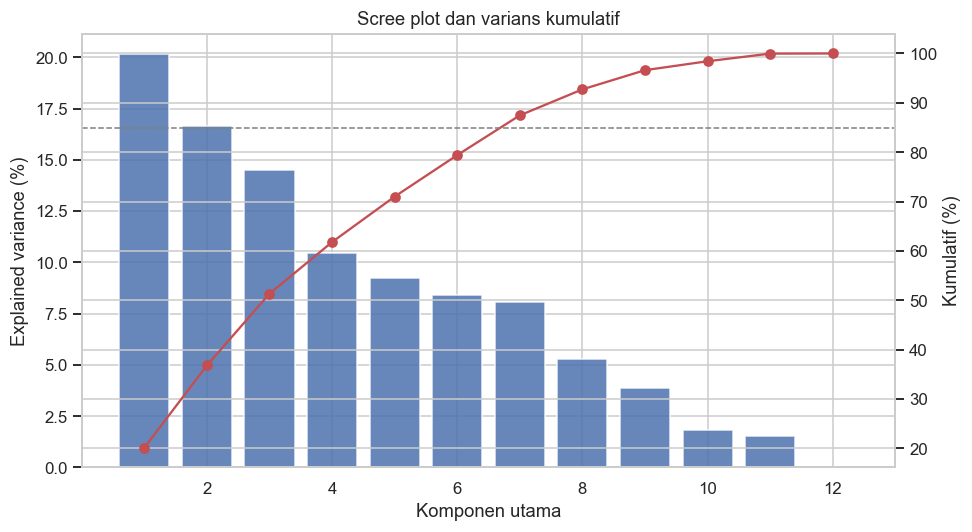


Loading komponen utama:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Usia,0.368,-0.270,0.186,-0.021,0.401,-0.076,0.065
Berat_Badan,0.327,0.538,-0.292,0.013,0.081,-0.019,0.030
Tinggi_Badan,0.152,0.316,-0.051,-0.293,0.076,-0.445,0.642
BMI,0.292,0.439,-0.319,0.186,0.047,0.224,-0.335
Tekanan_Sistolik,0.532,-0.180,0.103,-0.014,-0.287,0.041,-0.034
Tekanan_Diastolik,0.526,-0.169,0.108,0.052,-0.302,0.001,-0.109
Gula_Darah,-0.099,-0.051,-0.195,0.627,0.375,-0.132,-0.022
Kolesterol,0.245,-0.138,0.127,-0.150,0.694,0.172,-0.014
Detak_Jantung,-0.129,0.182,0.054,-0.543,0.128,0.495,-0.149
Lama_Rawat_Hari,-0.036,0.328,0.516,0.028,0.080,-0.303,-0.366


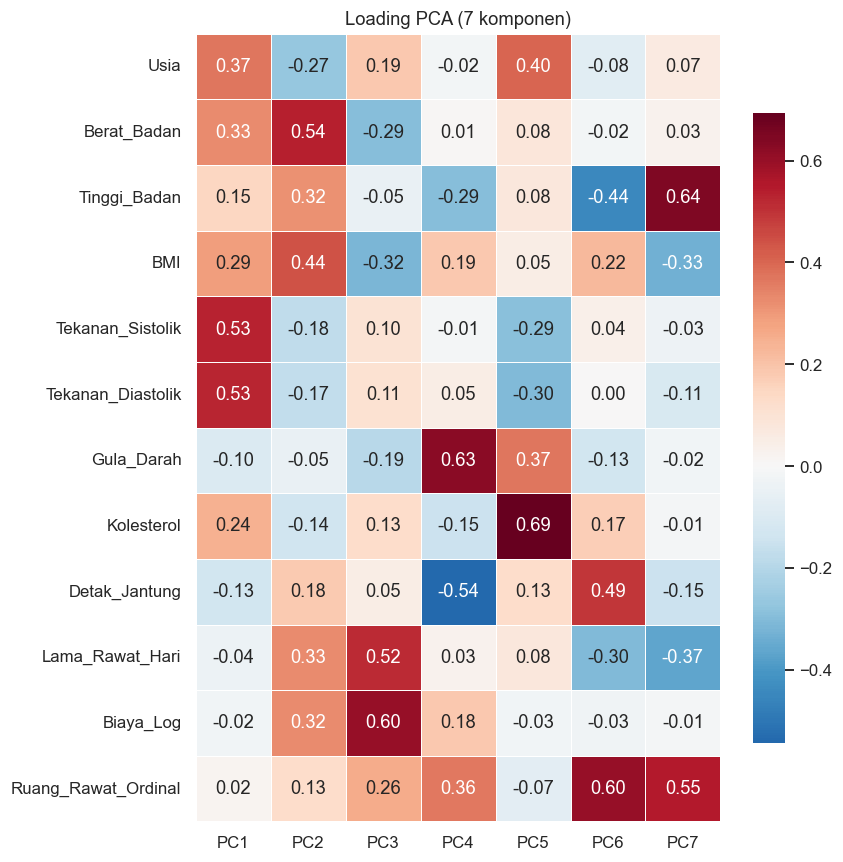


Kontribusi terbesar PC1:
Tekanan_Sistolik     0.532
Tekanan_Diastolik    0.526
Usia                 0.368
Berat_Badan          0.327
BMI                  0.292
Kolesterol           0.245

Kontribusi terbesar PC2:
Berat_Badan        0.538
BMI                0.439
Lama_Rawat_Hari    0.328
Biaya_Log          0.325
Tinggi_Badan       0.316
Usia              -0.270


In [16]:
fitur_pca = ["Usia", "Berat_Badan", "Tinggi_Badan", "BMI", "Tekanan_Sistolik",
             "Tekanan_Diastolik", "Gula_Darah", "Kolesterol", "Detak_Jantung",
             "Lama_Rawat_Hari", "Biaya_Log", "Ruang_Rawat_Ordinal"]
X = df[fitur_pca]
X_std = StandardScaler().fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_std)
evr = pca.explained_variance_ratio_
kumulatif = np.cumsum(evr)

pca_tbl = pd.DataFrame({
    "Komponen": [f"PC{i+1}" for i in range(len(evr))],
    "Eigenvalue": pca.explained_variance_.round(3),
    "Explained_Variance_Persen": (evr * 100).round(2),
    "Kumulatif_Persen": (kumulatif * 100).round(2),
})
display(pca_tbl)

n85 = int(np.argmax(kumulatif >= 0.85) + 1)
print("Jumlah komponen untuk >= 85% varians:", n85)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(range(1, len(evr) + 1), evr * 100, color="#4C72B0", alpha=0.85)
ax1.set_xlabel("Komponen utama")
ax1.set_ylabel("Explained variance (%)")
ax1.set_title("Scree plot dan varians kumulatif")
ax2 = ax1.twinx()
ax2.plot(range(1, len(evr) + 1), kumulatif * 100, color="#C44E52", marker="o")
ax2.axhline(85, color="gray", linestyle="--", linewidth=1)
ax2.set_ylabel("Kumulatif (%)")
plt.tight_layout()
plt.savefig("gambar/fig_scree.png", bbox_inches="tight")
plt.show()

loadings = pd.DataFrame(pca.components_[:n85].T, index=fitur_pca,
                        columns=[f"PC{i+1}" for i in range(n85)])
print("\nLoading komponen utama:")
display(loadings.round(3))

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title(f"Loading PCA ({n85} komponen)")
plt.tight_layout()
plt.savefig("gambar/fig_pca_loading.png", bbox_inches="tight")
plt.show()

for i in range(min(2, n85)):
    s = loadings[f"PC{i+1}"].sort_values(key=abs, ascending=False)
    print(f"\nKontribusi terbesar PC{i+1}:")
    print(s.head(6).round(3).to_string())


## 12. Dataset Akhir dan Ringkasan

**Input:** seluruh hasil pembersihan dan transformasi.  
**Proses:** menyimpan dataset bersih serta ringkasan angka penting untuk laporan.  
**Output:** `data_pasien_rs_bersih.csv`, `ringkasan.json`, dan beberapa gambar di folder `gambar/`.


In [17]:
def jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if obj is None:
        return None
    try:
        if pd.isna(obj):
            return None
    except (TypeError, ValueError):
        pass
    return obj

ringkasan = {
    "identitas": {"nama": "Muhammad Adi Indrawan", "nim": "3022410001",
                  "partner": "Muhammad Endi Saputra Ramadhan", "nim_partner": "3022410040"},
    "ukuran_awal": [int(df_raw.shape[0]), int(df_raw.shape[1])],
    "ukuran_setelah_cleaning": [int(df.shape[0]), int(len([c for c in df.columns if c not in ["Kelompok_Usia"]]))],
    "duplikat_persis_awal": n_exact_awal,
    "duplikat_id_awal": n_id_awal,
    "duplikat_persis_dihapus": n_exact_dihapus,
    "duplikat_id_dihapus": n_id_dihapus,
    "kolom_konstan": konstan,
    "kolom_mayoritas_kosong": mayoritas_kosong,
    "n_lb": n_lb, "n_gram": n_gram, "n_meter": n_meter, "n_rp": n_rp,
    "n_sentinel_999": n_sentinel_999, "n_tidak_ada": n_tidak_ada,
    "tanggal_terbalik": n_terbalik,
    "lama_tidak_konsisten": n_lama_mismatch,
    "missing_stats": stat_missing.round(3).to_dict(orient="records"),
    "missing_kategorik": cat_missing.to_dict(orient="records"),
    "kolesterol_per_usia": tabel_kol.round(3).to_dict(orient="records"),
    "outlier_iqr": outlier_tbl.round(3).to_dict(orient="records"),
    "biaya_sebelum": {k: float(v) for k, v in biaya_sebelum.items()},
    "biaya_sesudah": {k: float(v) for k, v in biaya_sesudah.items()},
    "biaya_capped": n_cap,
    "skew_biaya_sebelum": skew_sebelum,
    "skew_biaya_sesudah": skew_sesudah,
    "proporsi_readmisi": prop_readmisi.to_dict(),
    "proporsi_status": prop_status.to_dict(),
    "korelasi_kuat": pasangan.head(10).round(3).to_dict(orient="records"),
    "scaling": hasil_scaling.round(4).to_dict(orient="records"),
    "pca_variance": pca_tbl.round(3).to_dict(orient="records"),
    "pca_n85": n85,
    "pca_loadings": loadings.round(3).reset_index().rename(columns={"index": "Fitur"}).to_dict(orient="records"),
}
with open("ringkasan.json", "w", encoding="utf-8") as f:
    json.dump(jsonable(ringkasan), f, ensure_ascii=False, indent=2)

df.to_csv("data_pasien_rs_bersih.csv", index=False)
print("Dataset bersih:", df.shape)
print("File tersimpan: data_pasien_rs_bersih.csv, ringkasan.json")
print("Kolom akhir:")
print(list(df.columns))


Dataset bersih: (400, 29)
File tersimpan: data_pasien_rs_bersih.csv, ringkasan.json
Kolom akhir:
['Usia', 'Berat_Badan', 'Tinggi_Badan', 'BMI', 'Tekanan_Sistolik', 'Tekanan_Diastolik', 'Gula_Darah', 'Kolesterol', 'Detak_Jantung', 'Ruang_Rawat', 'Tanggal_Masuk', 'Tanggal_Keluar', 'Lama_Rawat_Hari', 'Biaya_Perawatan', 'Readmisi_30Hari', 'Status_Pulang', 'Biaya_Log', 'Ruang_Rawat_Ordinal', 'Readmisi', 'Status_Pulang_Code', 'Jenis_Kelamin_Perempuan', 'Diagnosis_Diabetes Melitus', 'Diagnosis_Gagal Jantung', 'Diagnosis_Hipertensi', 'Diagnosis_Pneumonia', 'Diagnosis_Stroke', 'Jenis_Asuransi_Swasta', 'Jenis_Asuransi_Umum', 'Kelompok_Usia']
